# Model evaluation

This notebook contains evalutation of different model types (linear regression, gradient boosting, and neural network) for both target variables.

As a preamble there's code for feature engineering, imputation, and encoding.

In [1]:
import numpy as np
import pandas as pd
import sklearn as sk
import numpy as np
import matplotlib.pyplot as plt
import matplotlib
import seaborn as sns

import os
import glob
from contextlib import contextmanager

The history saving thread hit an unexpected error (OperationalError('attempt to write a readonly database')).History will not be written to the database.


# Preamble

Helpers and feature engineering, same as model selection

In [2]:
if "get_ipython" not in globals() or "get_ipython" in globals() and get_ipython().__class__.__name__ == "TerminalInteractiveShell":
    matplotlib.use("Agg")
    plt.rcParams.update({"figure.dpi": 200})

def plot(figsize=(6.4, 4.8), **kwargs):
    plt.gcf().set_size_inches(*figsize)
    if "get_ipython" not in globals() or get_ipython().__class__.__name__ == "TerminalInteractiveShell":
        plt.savefig("a.png", **kwargs)
        plt.clf()
        plt.cla()
    else:
        plt.show()
    plt.close()

def dbg(x):
    print(x)
    return x

# https://stackoverflow.com/a/17511341
def ceildiv(a, b):
    return -(a // -b)

def nplots(n, cols, tight=None, figsize=None):
    rows = ceildiv(n, cols)
    figsize=figsize if figsize is not None else (6 * cols, 4 * rows)

    fig, axes = plt.subplots(rows, cols, figsize=figsize)

    for i, ax in enumerate(axes.flatten() if n != 1 else [axes]):
        if i >= n:
            fig.delaxes(ax)
            continue

        yield i, ax

    if tight != False and (n != 1 or tight == True):
        plt.tight_layout()

    plot(figsize=figsize)

@contextmanager
def oneplot(tight=None, figsize=None):
    for _, ax in nplots(1, 1, tight=tight, figsize=figsize):
        yield ax

sample_prev_df=None
sample_prev_n=None
sample_ret=None

def sample(df, n=400_000):
    global sample_prev_df
    global sample_prev_n
    global sample_ret

    if sample_prev_df is df and n == sample_prev_n:
        return sample_ret

    sample_ret = None
    sample_prev_df = df
    sample_prev_n = n

    return (sample_ret := df.sample(n, random_state=217, replace=False))

## Data loading

In [3]:
def load_clean(pat):
    return pd.concat([
        pd.read_csv(
            dbg(name),
            dtype=dict(
                VendorID=int,
                passenger_count=float,
                trip_distance=float,
                RatecodeID="category",
                # has NAs, but we're unlikely to use this column so
                # don't drop it
                store_and_fwd_flag="boolean",
                PULocationID="category",
                DOLocationID="category",
                payment_type=int,
                fare_amount=float,
                extra=float,
                mta_tax=float,
                tip_amount=float,
                tolls_amount=float,
                improvement_surcharge=float,
                total_amount=float,
                congestion_surcharge=float,
                Airport_fee=float,
                duration_hours=float,
                avg_speed_mph=float,
                fare_per_hour=float,
            ),
            parse_dates=[
                "tpep_pickup_datetime",
                "tpep_dropoff_datetime",
            ],
        )
        for name in sorted(glob.glob(f"../dataset-clean/{pat}"))
    ], ignore_index=True)

In [4]:
rides_train = load_clean("train_*")
# rides_sample = load_clean("sample_*")

../dataset-clean/train_00.csv
../dataset-clean/train_01.csv
../dataset-clean/train_02.csv
../dataset-clean/train_03.csv
../dataset-clean/train_04.csv
../dataset-clean/train_05.csv
../dataset-clean/train_06.csv
../dataset-clean/train_07.csv
../dataset-clean/train_08.csv
../dataset-clean/train_09.csv
../dataset-clean/train_10.csv
../dataset-clean/train_11.csv
../dataset-clean/train_12.csv
../dataset-clean/train_13.csv
../dataset-clean/train_14.csv


## Feature engineering

In [5]:
def group_zone_hour(
    df,
    aggs,
):
    """
    Aggregrate trips into zone-hour statistics

    df : pd.DataFrame
        Trip-level dataframe
    aggs : function, str, list, dict or None
        Argument to pd.DataFrameGroupBy.agg, specify which columsn and
        how aggregation should be done

    Returns:
    pd.DataFrame
        Dataframe with zone-hour and aggregated values
    """
    378798
    586920

    df = (
        df
            .groupby(["PULocationID", "pickup_hour"], observed=True)
            .agg(aggs)
            .reset_index()
    )
    # flaten column names
    df.columns = [(f"cur_{x}_{y}" if y else x) for (x, y) in df.columns]

    return df

def with_lags(
    df,
    feature,
    agg,
    window="2h",
    offsets=["1h"],
):
    agged = df.rename(
        columns=lambda x: x.removeprefix("cur_") if isinstance(x, str) else x,
    ).groupby("PULocationID", observed=True)[["pickup_hour", feature]].rolling(
        window,
        on="pickup_hour",
    ).agg(agg)

    for offset in offsets:
        df = pd.merge(
            df,
            agged.assign(
                pickup_hour=agged["pickup_hour"] +
                    (offset if not isinstance(offset, str) else pd.Timedelta(offset)),
            ).rename(
                columns=lambda x:
                    f"lag_{feature}-{agg}-{window}-{offset}" if x not in ["PULocationID", "pickup_hour"] else x,
            ),
            how="left",
            on=["PULocationID", "pickup_hour"],
        )

    return df

Define features (and lag parameters) for demand and revenue models

In [6]:
demand_lags = [
    ("count", "mean", "1h", ["23h", "24h", "48h"]),
    ("count", "mean", "1d", ["1d", "2d", "5d", "7d"]),

    ("duration_hours_sum", "mean", "1h", ["23h", "24h", "48h"]),
    ("duration_hours_sum", "mean", "1d", ["1d", "2d", "5d", "7d"]),

    ("trip_distance_sum", "mean", "1h", ["23h", "24h", "48h"]),
    ("trip_distance_sum", "mean", "1d", ["1d", "2d", "5d", "7d"]),

    ("avg_speed_mph_mean", "mean", "1h", ["23h", "24h", "48h"]),
    ("avg_speed_mph_mean", "mean", "1d", ["1d", "2d", "5d", "7d"]),

    ("tip_ratio_mean", "mean", "1h", ["23h", "24h", "48h"]),
    ("tip_ratio_mean", "mean", "1d", ["1d", "2d", "5d", "7d"]),

    ("ratecode_is_1_mean" , "mean", "2h", ["23h", "24h"]),
    ("ratecode_is_2_mean" , "mean", "2h", ["23h", "24h"]),
    ("ratecode_is_3_mean" , "mean", "2h", ["23h", "24h"]),
    ("ratecode_is_4_mean" , "mean", "2h", ["23h", "24h"]),
    ("ratecode_is_5_mean" , "mean", "2h", ["23h", "24h"]),
    ("ratecode_is_6_mean" , "mean", "2h", ["23h", "24h"]),
    ("ratecode_is_99_mean", "mean", "2h", ["23h", "24h"]),
    ("ratecode_is_1_mean" , "mean", "1d", ["1d", "2d"]),
    ("ratecode_is_2_mean" , "mean", "1d", ["1d", "2d"]),
    ("ratecode_is_3_mean" , "mean", "1d", ["1d", "2d"]),
    ("ratecode_is_4_mean" , "mean", "1d", ["1d", "2d"]),
    ("ratecode_is_5_mean" , "mean", "1d", ["1d", "2d"]),
    ("ratecode_is_6_mean" , "mean", "1d", ["1d", "2d"]),
    ("ratecode_is_99_mean", "mean", "1d", ["1d", "2d"]),

    ("do_is_upper_east_mean", "mean", "2h", ["23h", "24h"]),
    ("do_is_midtown_mean"   , "mean", "2h", ["23h", "24h"]),
    ("do_is_financial_mean" , "mean", "2h", ["23h", "24h"]),
    ("do_is_turtle_bay_mean", "mean", "2h", ["23h", "24h"]),
    ("do_is_north_mean"     , "mean", "2h", ["23h", "24h"]),
    ("do_is_upper_east_mean", "mean", "1d", ["1d", "2d"]),
    ("do_is_midtown_mean"   , "mean", "1d", ["1d", "2d"]),
    ("do_is_financial_mean" , "mean", "1d", ["1d", "2d"]),
    ("do_is_turtle_bay_mean", "mean", "1d", ["1d", "2d"]),
    ("do_is_north_mean"     , "mean", "1d", ["1d", "2d"]),
]

revenue_lags = [
    ("fare_amount_mean", "mean", "1h", ["23h", "24h", "48h"]),
    ("fare_amount_mean", "mean", "1d", ["1d", "2d", "5d", "7d"]),

    ("duration_hours_mean", "mean", "1h", ["23h", "24h", "48h"]),
    ("duration_hours_mean", "mean", "1d", ["1d", "2d", "5d", "7d"]),

    ("trip_distance_mean", "mean", "1h", ["23h", "24h", "48h"]),
    ("trip_distance_mean", "mean", "1d", ["1d", "2d", "5d", "7d"]),

    ("avg_speed_mph_mean", "mean", "1h", ["23h", "24h", "48h"]),
    ("avg_speed_mph_mean", "mean", "1d", ["1d", "2d", "5d", "7d"]),

    ("tip_ratio_mean", "mean", "1h", ["23h", "24h", "48h"]),
    ("tip_ratio_mean", "mean", "1d", ["1d", "2d", "5d", "7d"]),

    ("ratecode_is_1_mean" , "mean", "2h", ["23h", "24h"]),
    ("ratecode_is_2_mean" , "mean", "2h", ["23h", "24h"]),
    ("ratecode_is_3_mean" , "mean", "2h", ["23h", "24h"]),
    ("ratecode_is_4_mean" , "mean", "2h", ["23h", "24h"]),
    ("ratecode_is_5_mean" , "mean", "2h", ["23h", "24h"]),
    ("ratecode_is_6_mean" , "mean", "2h", ["23h", "24h"]),
    ("ratecode_is_99_mean", "mean", "2h", ["23h", "24h"]),
    ("ratecode_is_1_mean" , "mean", "1d", ["1d", "2d"]),
    ("ratecode_is_2_mean" , "mean", "1d", ["1d", "2d"]),
    ("ratecode_is_3_mean" , "mean", "1d", ["1d", "2d"]),
    ("ratecode_is_4_mean" , "mean", "1d", ["1d", "2d"]),
    ("ratecode_is_5_mean" , "mean", "1d", ["1d", "2d"]),
    ("ratecode_is_6_mean" , "mean", "1d", ["1d", "2d"]),
    ("ratecode_is_99_mean", "mean", "1d", ["1d", "2d"]),

    ("do_is_upper_east_mean", "mean", "2h", ["23h", "24h"]),
    ("do_is_midtown_mean"   , "mean", "2h", ["23h", "24h"]),
    ("do_is_financial_mean" , "mean", "2h", ["23h", "24h"]),
    ("do_is_turtle_bay_mean", "mean", "2h", ["23h", "24h"]),
    ("do_is_north_mean"     , "mean", "2h", ["23h", "24h"]),
    ("do_is_upper_east_mean", "mean", "1d", ["1d", "2d"]),
    ("do_is_midtown_mean"   , "mean", "1d", ["1d", "2d"]),
    ("do_is_financial_mean" , "mean", "1d", ["1d", "2d"]),
    ("do_is_turtle_bay_mean", "mean", "1d", ["1d", "2d"]),
    ("do_is_north_mean"     , "mean", "1d", ["1d", "2d"]),
]

In [7]:
numerical_pipeline = sk.pipeline.Pipeline([
    ("imputer", sk.impute.SimpleImputer(strategy="mean")),
    ("scaler", sk.preprocessing.QuantileTransformer()),
])

full_pipeline = sk.compose.ColumnTransformer([
    (
        "num",
        numerical_pipeline,
        sk.compose.make_column_selector(dtype_include=np.float64),
    ),
    (
        "cat_ohe",
        sk.preprocessing.OneHotEncoder(),
        ["PULocationID", "pickup_hour_of_day"],
    ),
], remainder="drop")

Put together all data processing from the cleaned row-level data

In [8]:
zone_upper_east = [str(x) for x in [236, 237, 141, 142, 262]]
zone_midtown = [str(x) for x in [161, 162, 163]]
zone_financial = [str(x) for x in [12, 88, 87, 261]]
zone_turtle_bay = [str(x) for x in [162, 229]]
zone_north = [str(x) for x in [42, 116, 127, 243, 255]]

def build_xy(rides_clean, y_col, lags):
    rides_feat = rides_clean.assign(
        pickup_hour = lambda x: x["tpep_pickup_datetime"].dt.floor("1h"),
        pickup_hour_of_day = lambda x:
            x["tpep_pickup_datetime"].dt.hour +
            (x["tpep_pickup_datetime"].dt.minute / 60),
        # monday = 0
        pickup_day_of_week = lambda x:
            (x["tpep_pickup_datetime"].dt.day_of_week) +
            (x["tpep_pickup_datetime"].dt.hour / 24) +
            (x["tpep_pickup_datetime"].dt.minute / (60 * 24)),
        ratecode_is_airport = lambda x: x["RatecodeID"].isin(["2", "3"]),
        # total amount includes extra surcharges/fees => stronger patterns tip %
        tip_ratio = lambda x: (x["tip_amount"] / (x["total_amount"] - x["tip_amount"])).fillna(0),
    )

    rides_hour = group_zone_hour(
        pd.concat(
            [
                rides_feat,
                pd.get_dummies(rides_feat["RatecodeID"], prefix="ratecode_is"),
                pd.DataFrame(dict(
                    do_is_upper_east=rides_feat["DOLocationID"].isin(zone_upper_east),
                    do_is_midtown=rides_feat["DOLocationID"].isin(zone_midtown),
                    do_is_financial=rides_feat["DOLocationID"].isin(zone_financial),
                    do_is_turtle_bay=rides_feat["DOLocationID"].isin(zone_turtle_bay),
                    do_is_north=rides_feat["DOLocationID"].isin(zone_north),
                ))
            ],
            axis=1,
        ),
        dict(
            passenger_count="mean",
            trip_distance=["sum", "mean"],
            # amount without tips or fees
            fare_amount=["sum", "mean"],
            # the following are somewhat fixed fees so the means
            # are losely counts of rides where the fee is charged
            # not much info intrinsically but maybe a patern?
            mta_tax="mean",
            tolls_amount="mean",
            improvement_surcharge="mean",
            congestion_surcharge="mean",
            Airport_fee="mean",
            # total amount including tips and fees
            # * in our case these are "noise" when making predictions
            # * if we really wanted to be vultures we might look at tips
            #   as an indicator of routes where we could charge more
            total_amount=["sum", "mean"],
            tip_amount="mean",
            tip_ratio="mean",
            # probably correlated with demand
            # * count used in this column arbitrarily
            duration_hours=["count", "sum", "mean"],
            avg_speed_mph="mean",
            fare_per_hour="mean",
            ratecode_is_airport=["mean", "count"],

            ratecode_is_1="mean",
            ratecode_is_2="mean",
            ratecode_is_3="mean",
            ratecode_is_4="mean",
            ratecode_is_5="mean",
            ratecode_is_6="mean",
            ratecode_is_99="mean",

            do_is_upper_east="mean",
            do_is_midtown="mean",
            do_is_financial="mean",
            do_is_turtle_bay="mean",
            do_is_north="mean",
        ),
    ).assign(
        pickup_hour_of_day=lambda x: x["pickup_hour"].dt.hour,
    ).rename(
        columns=dict(
            cur_duration_hours_count="cur_count",
        )
    )

    X = rides_hour

    for feat, agg, window, offsets in lags:
        X = with_lags(
            X,
            feat,
            agg,
            window=window,
            offsets=offsets,
        )

    index_cols = [
        "PULocationID",
        "pickup_hour",
        "pickup_hour_of_day",
    ]

    y = X[y_col]
    X = X.drop(columns=[
        x
        for x in X.columns
        if x.startswith("cur_")
    ])

    assert all((x.startswith("lag_") or x in index_cols) for x in X.columns)

    return X, y

## Helper for model evaluation

For each model, train 5 times on different folds (validation/train splits of the same dataset) and return a dataframe of the performance from each one. The class also keeps a validation dataset not used during 5-fold validation to evaluate the best performing model on unseen data.

In [9]:
class Eval:
    def __init__(self, xy):
        self.X, self.y = xy
        self.X = sk.clone(full_pipeline).fit_transform(
            self.X.toarray() if hasattr(self.X, "toarray") else self.X,
        )

        [(self.train_idx, self.valid_idx)] = sk.model_selection.ShuffleSplit(
            n_splits=1,
            test_size=0.1,
            random_state=2718,
        ).split(
            self.X,
            y=self.y,
        )


    def eval(self, m):
        xv = sk.model_selection.cross_validate(
            m,
            self.X[self.train_idx],
            self.y[self.train_idx],
            cv=5,
            scoring="neg_mean_squared_error",
            return_estimator=True,
            return_train_score=True,
            n_jobs=-1,
            verbose=10,
        )

        print(m)
        print(xv)
        print(np.min(np.sqrt(-xv["test_score"])))

        best = xv["estimator"][np.argmin(xv["test_score"])]

        return xv, str(best), pd.DataFrame(dict(
            pred = best.predict(self.X[self.valid_idx]),
            actual = self.y[self.valid_idx],
            model = str(best),
        ))

## Eval off-the-shelf models for demand

[Parallel(n_jobs=-1)]: Using backend LokyBackend with 10 concurrent workers.
[Parallel(n_jobs=-1)]: Done   2 out of   5 | elapsed:    6.5s remaining:    9.8s
[Parallel(n_jobs=-1)]: Done   3 out of   5 | elapsed:    6.6s remaining:    4.4s
[Parallel(n_jobs=-1)]: Done   5 out of   5 | elapsed:    6.6s finished


LinearRegression()
{'fit_time': array([3.73599315, 2.55638719, 3.69494724, 3.72694874, 3.74673676]), 'score_time': array([0.28622484, 0.05830503, 0.05974603, 0.3033669 , 0.29757214]), 'estimator': [LinearRegression(), LinearRegression(), LinearRegression(), LinearRegression(), LinearRegression()], 'test_score': array([-2180.45101125, -2117.75382745, -2160.98447493, -2141.24185823,
       -2156.96076357]), 'train_score': array([-2142.00544388, -2157.7483688 , -2146.85599949, -2151.79955969,
       -2147.80525413])}
46.0190593933755


[Parallel(n_jobs=-1)]: Using backend LokyBackend with 10 concurrent workers.
[Parallel(n_jobs=-1)]: Done   2 out of   5 | elapsed:   33.0s remaining:   49.5s
[Parallel(n_jobs=-1)]: Done   3 out of   5 | elapsed:   33.1s remaining:   22.0s
[Parallel(n_jobs=-1)]: Done   5 out of   5 | elapsed:   33.8s finished


HistGradientBoostingRegressor()
{'fit_time': array([25.97350287, 26.80531883, 26.43339491, 26.10376096, 26.37263298]), 'score_time': array([1.1830349 , 1.13864923, 1.19538999, 1.17971921, 1.13737607]), 'estimator': [HistGradientBoostingRegressor(), HistGradientBoostingRegressor(), HistGradientBoostingRegressor(), HistGradientBoostingRegressor(), HistGradientBoostingRegressor()], 'test_score': array([ -995.03058091,  -953.58954996, -1002.46089072,  -955.65489705,
        -964.50824554]), 'train_score': array([-901.39909517, -912.79738259, -901.82004721, -909.85718338,
       -903.67700701])}
30.88024530279416


[Parallel(n_jobs=-1)]: Using backend LokyBackend with 10 concurrent workers.
/nix/store/p9ny36zcy47qrh4wyr0prwx0i04w2sv3-python3-3.13.12-env/lib/python3.13/site-packages/sklearn/neural_network/_multilayer_perceptron.py:785: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (200) reached and the optimization hasn't converged yet.
  warnings.warn(
/nix/store/p9ny36zcy47qrh4wyr0prwx0i04w2sv3-python3-3.13.12-env/lib/python3.13/site-packages/sklearn/neural_network/_multilayer_perceptron.py:785: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (200) reached and the optimization hasn't converged yet.
  warnings.warn(
[Parallel(n_jobs=-1)]: Done   2 out of   5 | elapsed:  1.6min remaining:  2.4min
/nix/store/p9ny36zcy47qrh4wyr0prwx0i04w2sv3-python3-3.13.12-env/lib/python3.13/site-packages/sklearn/neural_network/_multilayer_perceptron.py:785: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (200) reached and the optimization hasn't converged yet.
  warnings.wa

MLPRegressor(hidden_layer_sizes=(25, 25, 10))
{'fit_time': array([97.83920097, 97.55248094, 97.90551496, 99.60173798, 97.33020592]), 'score_time': array([0.04119897, 0.04808712, 0.04001212, 0.03696513, 0.04649091]), 'estimator': [MLPRegressor(hidden_layer_sizes=(25, 25, 10)), MLPRegressor(hidden_layer_sizes=(25, 25, 10)), MLPRegressor(hidden_layer_sizes=(25, 25, 10)), MLPRegressor(hidden_layer_sizes=(25, 25, 10)), MLPRegressor(hidden_layer_sizes=(25, 25, 10))], 'test_score': array([-667.48408166, -663.77748732, -746.75014839, -668.70217005,
       -681.27475208]), 'train_score': array([-595.094895  , -596.017386  , -646.35223696, -593.74720465,
       -603.90936198])}
25.763879508406514


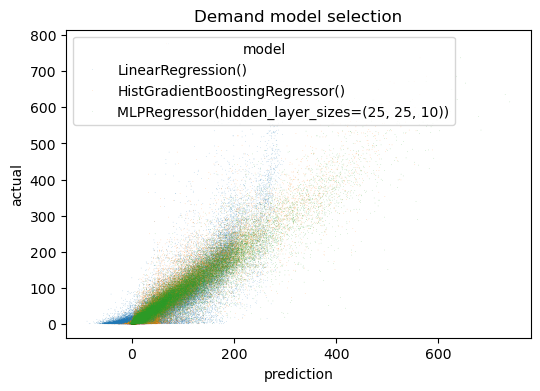

In [10]:
demand_eval = Eval(
    build_xy(rides_train, "cur_count", demand_lags),
)

results = [
    demand_eval.eval(m)
    for m in [
        sk.linear_model.LinearRegression(),
        sk.ensemble.HistGradientBoostingRegressor(),
        sk.neural_network.MLPRegressor(hidden_layer_sizes=(25, 25, 10)), # Deeper and less parameters than default 100
    ]
]

with oneplot() as ax:
    sns.scatterplot(
        ax=ax,
        data=pd.concat([x[2] for x in results], ignore_index=True),
        x="pred",
        y="actual",
        hue="model",
        s=0.2,
        alpha=0.5,
        linewidth=0,
    ),
    ax.set_xlabel("prediction")
    ax.set_ylabel("actual")
    ax.set_title("Demand model selection")

Losses per model, per fold

In [11]:
pd.DataFrame({ x[1] : x[0]["test_score"] for x in results })

,LinearRegression(),HistGradientBoostingRegressor(),"MLPRegressor(hidden_layer_sizes=(25, 25, 10))"
0,-2180.451011,-995.030581,-667.484082
1,-2117.753827,-953.589550,-663.777487
2,-2160.984475,-1002.460891,-746.750148
3,-2141.241858,-955.654897,-668.702170
4,-2156.960764,-964.508246,-681.274752


Loss summary per model

In [12]:
pd.DataFrame({ x[1] : x[0]["test_score"] for x in results }).describe()

,LinearRegression(),HistGradientBoostingRegressor(),"MLPRegressor(hidden_layer_sizes=(25, 25, 10))"
count,5.000000,5.000000,5.000000
mean,-2151.478387,-974.248833,-685.597728
std,23.462564,22.886791,34.813767
min,-2180.451011,-1002.460891,-746.750148
25%,-2160.984475,-995.030581,-681.274752
50%,-2156.960764,-964.508246,-668.702170
75%,-2141.241858,-955.654897,-667.484082
max,-2117.753827,-953.589550,-663.777487


# Eval off-the-shelf models for revenue

[Parallel(n_jobs=-1)]: Using backend LokyBackend with 10 concurrent workers.
[Parallel(n_jobs=-1)]: Done   2 out of   5 | elapsed:    4.6s remaining:    6.9s
[Parallel(n_jobs=-1)]: Done   3 out of   5 | elapsed:    4.6s remaining:    3.1s
[Parallel(n_jobs=-1)]: Done   5 out of   5 | elapsed:    6.3s finished


LinearRegression()
{'fit_time': array([2.85158014, 3.38807726, 3.43175983, 3.41830111, 3.22017884]), 'score_time': array([0.0386498 , 0.239434  , 0.18769217, 0.19638801, 0.21634936]), 'estimator': [LinearRegression(), LinearRegression(), LinearRegression(), LinearRegression(), LinearRegression()], 'test_score': array([-33.68065279, -33.72960081, -31.92616514, -33.23990997,
       -32.90385115]), 'train_score': array([-32.89700623, -32.88504532, -33.33490534, -33.00685887,
       -33.09029064])}
5.65032433935348


[Parallel(n_jobs=-1)]: Using backend LokyBackend with 10 concurrent workers.
[Parallel(n_jobs=-1)]: Done   2 out of   5 | elapsed:   30.8s remaining:   46.1s
[Parallel(n_jobs=-1)]: Done   3 out of   5 | elapsed:   31.1s remaining:   20.7s
[Parallel(n_jobs=-1)]: Done   5 out of   5 | elapsed:   31.9s finished


HistGradientBoostingRegressor()
{'fit_time': array([24.58143687, 24.63919425, 23.69109011, 23.6262548 , 24.16596508]), 'score_time': array([1.13453126, 1.0615418 , 1.14837074, 1.14372993, 1.09928083]), 'estimator': [HistGradientBoostingRegressor(), HistGradientBoostingRegressor(), HistGradientBoostingRegressor(), HistGradientBoostingRegressor(), HistGradientBoostingRegressor()], 'test_score': array([-32.80516573, -33.08040166, -31.25878034, -32.65962525,
       -32.33546406]), 'train_score': array([-30.25746491, -30.14783061, -30.66267914, -30.23949356,
       -30.35167   ])}
5.590955226184804


[Parallel(n_jobs=-1)]: Using backend LokyBackend with 10 concurrent workers.
/nix/store/p9ny36zcy47qrh4wyr0prwx0i04w2sv3-python3-3.13.12-env/lib/python3.13/site-packages/sklearn/neural_network/_multilayer_perceptron.py:785: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (200) reached and the optimization hasn't converged yet.
  warnings.warn(
/nix/store/p9ny36zcy47qrh4wyr0prwx0i04w2sv3-python3-3.13.12-env/lib/python3.13/site-packages/sklearn/neural_network/_multilayer_perceptron.py:785: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (200) reached and the optimization hasn't converged yet.
  warnings.warn(
[Parallel(n_jobs=-1)]: Done   2 out of   5 | elapsed:  1.5min remaining:  2.3min
/nix/store/p9ny36zcy47qrh4wyr0prwx0i04w2sv3-python3-3.13.12-env/lib/python3.13/site-packages/sklearn/neural_network/_multilayer_perceptron.py:785: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (200) reached and the optimization hasn't converged yet.
  warnings.wa

MLPRegressor(hidden_layer_sizes=(25, 25, 10))
{'fit_time': array([93.30570531, 92.19449806, 92.86741209, 92.29950786, 95.39321899]), 'score_time': array([0.01883483, 0.03080297, 0.01929307, 0.03225493, 0.02707577]), 'estimator': [MLPRegressor(hidden_layer_sizes=(25, 25, 10)), MLPRegressor(hidden_layer_sizes=(25, 25, 10)), MLPRegressor(hidden_layer_sizes=(25, 25, 10)), MLPRegressor(hidden_layer_sizes=(25, 25, 10)), MLPRegressor(hidden_layer_sizes=(25, 25, 10))], 'test_score': array([-34.25108113, -35.39079326, -32.39152948, -35.06982667,
       -34.57419867]), 'train_score': array([-27.37271465, -27.27379584, -28.07237585, -27.09609713,
       -27.12875553])}
5.69135567991167


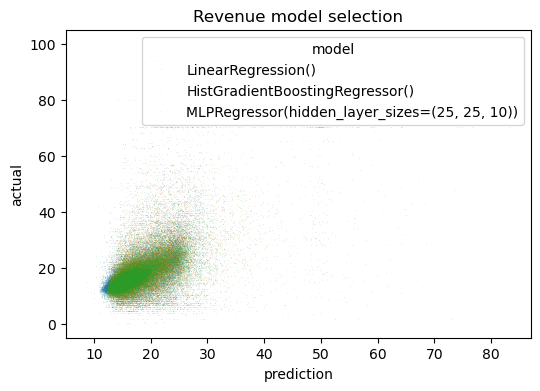

In [13]:
revenue_eval = Eval(
    build_xy(rides_train, "cur_fare_amount_mean", revenue_lags),
)
results = [
    revenue_eval.eval(m)
    for m in [
        sk.linear_model.LinearRegression(),
        sk.ensemble.HistGradientBoostingRegressor(),
        sk.neural_network.MLPRegressor(hidden_layer_sizes=(25, 25, 10)),
    ]
]

with oneplot() as ax:
    sns.scatterplot(
        ax=ax,
        data=pd.concat([x[2] for x in results], ignore_index=True),
        x="pred",
        y="actual",
        hue="model",
        s=0.2,
        alpha=0.5,
        linewidth=0,
    ),
    ax.set_xlabel("prediction")
    ax.set_ylabel("actual")
    ax.set_title("Revenue model selection")

Losses per model, per fold

In [14]:
pd.DataFrame({ x[1] : x[0]["test_score"] for x in results })

,LinearRegression(),HistGradientBoostingRegressor(),"MLPRegressor(hidden_layer_sizes=(25, 25, 10))"
0,-33.680653,-32.805166,-34.251081
1,-33.729601,-33.080402,-35.390793
2,-31.926165,-31.258780,-32.391529
3,-33.239910,-32.659625,-35.069827
4,-32.903851,-32.335464,-34.574199


Losses per model, per fold

In [15]:
pd.DataFrame({ x[1] : x[0]["test_score"] for x in results }).describe()

,LinearRegression(),HistGradientBoostingRegressor(),"MLPRegressor(hidden_layer_sizes=(25, 25, 10))"
count,5.000000,5.000000,5.000000
mean,-33.096036,-32.427887,-34.335486
std,0.736446,0.706606,1.172178
min,-33.729601,-33.080402,-35.390793
25%,-33.680653,-32.805166,-35.069827
50%,-33.239910,-32.659625,-34.574199
75%,-32.903851,-32.335464,-34.251081
max,-31.926165,-31.258780,-32.391529


# Summary

Demand:
* NN outperforms other models

Revenue:
* Models perform similarly, use gradient boosting as it could potentially improve over linear regression with less computational cost than NN